## Tarea #: 1 (Machine learning 1. Especialización de Big Data y Analytics)

Tema: Exploración avanzada de datos, PCA, regresión y análisis crítico multivariado

Por: Maria Alejandra Colorado Ríos


## Punto 1.1.

Calcular la media, mediana, desviación estándar, moda y el número de repeticiones de la moda para las variables numéricas y categóricas del dataset. Realice un análisis crítico detallado sobre las implicaciones de estas medidas de tendencia central y dispersión respecto a la distribución e inequidad socioeconómica entre las ciudades.

Importar y preparar los datos

In [1]:
from pathlib import Path

import pandas as pd

ruta = Path("../../docs/analisisCiudades.xlsx")
datos = pd.read_excel(ruta, sheet_name="datos_originales")
print(f"Archivo: {ruta.as_posix()}")
print(f"Ciudades: {len(datos)}")
#datos

Archivo: ../../docs/analisisCiudades.xlsx
Ciudades: 30


Separar las variables numéricas y categóricas

In [2]:
# Variables numéricas
variables_numericas = [
    'GDP (USD Billion)',
    'Population (Millions)',
    'Unemployment Rate (%)',
    'Average Age',
    'Women (%)',
    'Men (%)',
    'Budget (USD Billion)'
]

# Variables categóricas
variables_categoricas = [
    'City',
    'Initial label',
    'Training'
]

Calcular las medidas para variables numéricas

In [3]:
# Crear una lista para almacenar resultados
resultados_numericos = []

for variable in variables_numericas:

    serie = datos[variable].dropna()

    # Calcular frecuencias
    frecuencias = serie.value_counts()

    # Identificar frecuencia máxima
    frecuencia_maxima = frecuencias.max()

    # Obtener todas las modas
    modas = frecuencias[frecuencias == frecuencia_maxima].index.tolist()

    # Identificar si existe una moda real
    if frecuencia_maxima == 1:
        moda = "Sin moda"
        frecuencia_moda = 0
    else:
        moda = modas
        frecuencia_moda = frecuencia_maxima

    resultados_numericos.append({
        'Variable': variable,
        'n': len(serie),
        'Media': serie.mean(),
        'Mediana': serie.median(),
        'Desviación estándar': serie.std(ddof=0),
        'Moda': moda,
        'Frecuencia de la moda': frecuencia_moda
    })

# Crear DataFrame de resultados
tabla_numerica = pd.DataFrame(resultados_numericos)

# Mostrar resultados
display(tabla_numerica.round(4))

,Variable,n,Media,Mediana,Desviación estándar,Moda,Frecuencia de la moda
0,GDP (USD Billion),30,8.7500,2.65,19.5797,Sin moda,0
1,Population (Millions),30,0.7310,0.39,1.3301,"[0.08, 0.01]",2
2,Unemployment Rate (%),30,13.8333,13.45,2.8956,Sin moda,0
3,Average Age,30,29.2333,29.00,2.2013,[29],6
4,Women (%),30,51.5000,51.00,0.7638,[51],14
5,Men (%),30,48.5000,49.00,0.7638,[49],14
6,Budget (USD Billion),30,1.6500,0.60,3.3932,"[0.5, 0.1]",3


Calcular las medidas para variables categóricas

In [4]:
resultados_categoricos = []

for variable in variables_categoricas:

    serie = datos[variable].dropna()

    # Calcular frecuencias
    frecuencias = serie.value_counts()

    # Frecuencia máxima
    frecuencia_maxima = frecuencias.max()

    # Obtener todas las categorías modales
    modas = frecuencias[frecuencias == frecuencia_maxima].index.tolist()

    # Identificar si existe una moda real
    if frecuencia_maxima == 1:
        moda = "Sin moda"
        frecuencia_moda = 0
        porcentaje_moda = 0
    else:
        moda = modas
        frecuencia_moda = frecuencia_maxima
        porcentaje_moda = (frecuencia_maxima / len(serie)) * 100

    resultados_categoricos.append({
        'Variable': variable,
        'n': len(serie),
        'Moda': moda,
        'Frecuencia de la moda': frecuencia_moda,
        'Porcentaje de la moda': porcentaje_moda
    })

# Crear DataFrame de resultados
tabla_categorica = pd.DataFrame(resultados_categoricos)

# Mostrar resultados
display(tabla_categorica.round(2))

,Variable,n,Moda,Frecuencia de la moda,Porcentaje de la moda
0,City,30,Sin moda,0,0.00
1,Initial label,30,[2],10,33.33
2,Training,30,[Yes],21,70.00


# Análisis punto 1.1

1. Concentración económica y distribución del PIB (GDP)

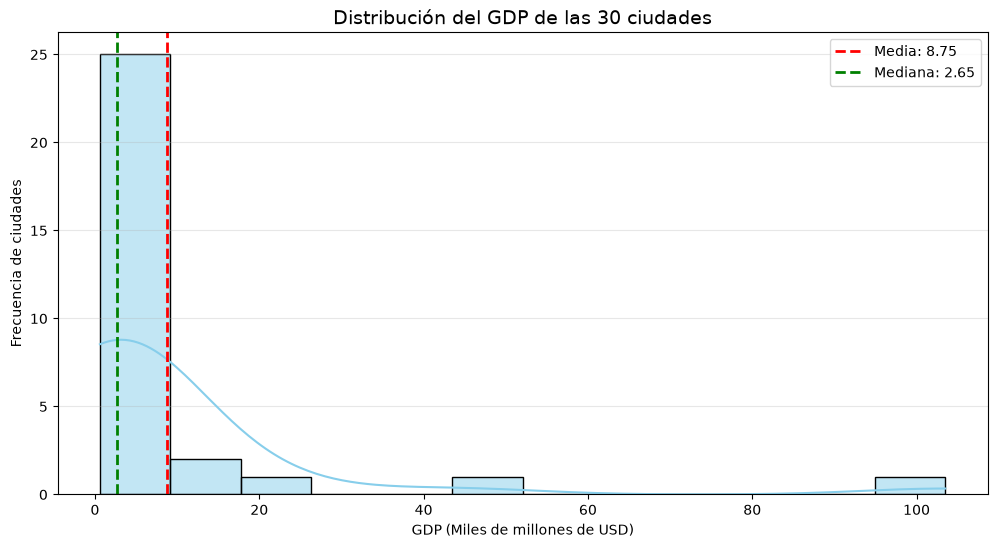

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar la variable GDP
gdp = datos["GDP (USD Billion)"].dropna()

# Calcular medidas estadísticas
media = gdp.mean()
mediana = gdp.median()

# Crear el histograma
plt.figure(figsize=(12, 6))

sns.histplot(
    gdp,
    bins=12,
    kde=True,
    color="skyblue",
    edgecolor="black"
)

# Agregar línea de la media
plt.axvline(
    media,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media:.2f}"
)

# Agregar línea de la mediana
plt.axvline(
    mediana,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {mediana:.2f}"
)

# Configurar el gráfico
plt.title("Distribución del GDP de las 30 ciudades", fontsize=14)
plt.xlabel("GDP (Miles de millones de USD)")
plt.ylabel("Frecuencia de ciudades")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()


Se identifica que la media(8,75) es considerablemente superior a la mediana (2.65) para la variable GDP, lo que indica que la distribución está sesgada a la derecha, es decir, existen pocas ciudades con valor total de bienes y servicios producidos muy elevados que incrementan el promedio general. 

Por ejemplo, Bogotá registra un GDP de 103,5 mil millones de dólares, y Medellín de 44,1, mientras que la mayoría de las ciudades presentan valores inferiores a 10 mil millones.

Adicional, la desviación estándar de 19,57 mil millones supera ampliamente la media, lo que evidencia una dispersión muy alta de los datos.

Por lo tanto, esta concentración refleja una posible desigual económica entre ciudades, evidenciadas en sus capacidades productivas, niveles de generación de empleo, inversión y desarrollo empresarial.


2. Diferencias en el tamaño poblacional

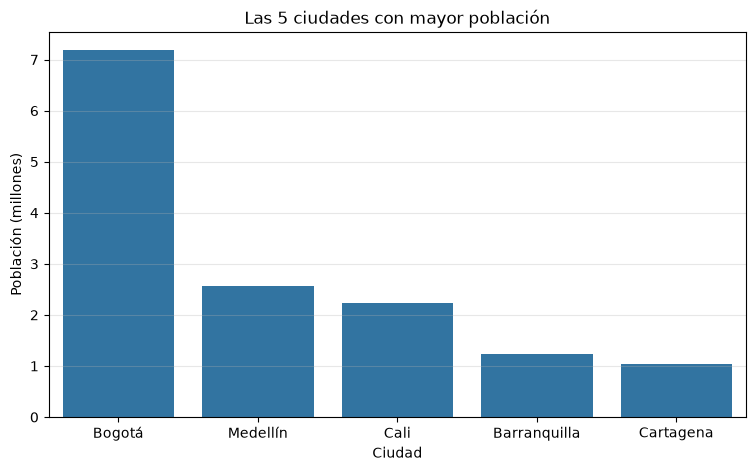

In [6]:

# Seleccionar las 10 ciudades más pobladas
top_5 = datos.nlargest(
    5,
    "Population (Millions)"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_5,
    x="City",
    y="Population (Millions)"
)

plt.title("Las 5 ciudades con mayor población")
plt.xlabel("Ciudad")
plt.ylabel("Población (millones)")
plt.grid(axis="y", alpha=0.3)

plt.show()


La población presenta un comportamiento similar al GDP, en donde se evidencia que la media es superior a la mediana y la desviación estándar es elevada.
Esto significa que, existen grandes diferencias en el tamaño poblacional de las ciudades. Por ejemplo, Bogotá, Medellín y Cali, concentran una cantidad importante de habitantes, mientras que otras presentan poblaciones menores.


### Análisis punto 1.1

Conclusión final:
El análisis estadístico de las 30 ciudades evidencia una marcada heterogeneidad socioeconómica, reflejada en la concentración de la actividad económica, la población y los recursos presupuestales en un grupo reducido de territorios. Esto se observa en las diferencias entre la media y la mediana, así como en las elevadas desviaciones estándar.
Asimismo, las tasas de desempleo presentan diferencias territoriales que pueden reflejar desigualdades en las oportunidades laborales. En contraste, variables demográficas como la edad promedio y la composición por sexo muestran un comportamiento más homogéneo.
En general, los resultados permiten identificar brechas territoriales en el desarrollo económico y la distribución de los recursos. No obstante, para evaluar con mayor profundidad las condiciones de vida y la distribución de la riqueza entre los habitantes, sería necesario complementar el análisis con indicadores como el PIB per cápita, la pobreza, el coeficiente de Gini y la informalidad laboral.


## Punto 1.2.

Generar un boxplot para analizar la distribución de las variables clave de la Tabla 1 utilizando las proporciones indicadas a continuación. Identifique y discuta formalmente la presencia de valores atípicos (outliers), su impacto analítico y su interpretación socioeconómica en el contexto urbano.


Generación de los boxplots

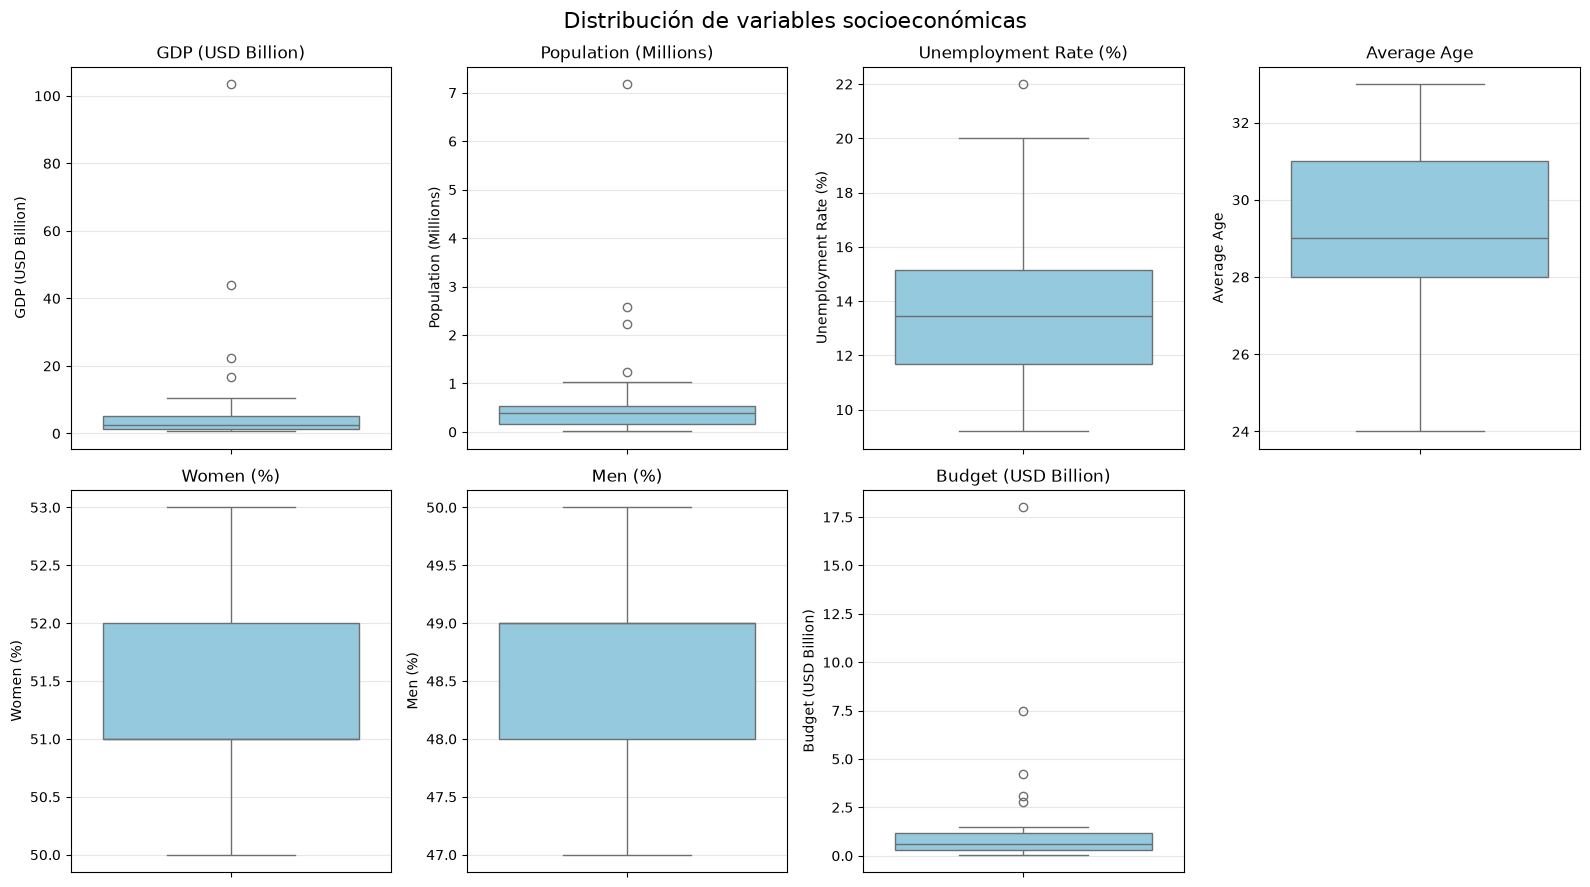

In [7]:

# Generar boxplots para todas las variables numéricas

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()

for i, variable in enumerate(variables_numericas):
    sns.boxplot(
        y=datos[variable],
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(variable)
    axes[i].grid(axis="y", alpha=0.3)

# Ocultar el gráfico sobrante
axes[-1].axis("off")

plt.suptitle(
    "Distribución de variables socioeconómicas",
    fontsize=16
)

plt.tight_layout()
plt.show()


Identificar formalmente los valores atípicos

In [8]:

resultados_outliers = []

for variable in variables_numericas:

    q1 = datos[variable].quantile(0.25)
    q3 = datos[variable].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    # Identificar ciudades con valores atípicos
    atipicos = datos[
        (datos[variable] < limite_inferior) |
        (datos[variable] > limite_superior)
    ]

    resultados_outliers.append({
        "Variable": variable,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Cantidad outliers": len(atipicos),
        "Ciudades": ", ".join(atipicos["City"])
    })

tabla_outliers = pd.DataFrame(resultados_outliers)

display(tabla_outliers.round(2))


,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Cantidad outliers,Ciudades
0,GDP (USD Billion),1.35,5.02,3.67,-4.16,10.54,4,"Bogotá, Medellín, Cali, Barranquilla"
1,Population (Millions),0.16,0.53,0.37,-0.39,1.08,4,"Bogotá, Medellín, Cali, Barranquilla"
2,Unemployment Rate (%),11.70,15.15,3.45,6.52,20.32,1,Puerto Carreño
3,Average Age,28.00,31.00,3.00,23.50,35.50,0,
4,Women (%),51.00,52.00,1.00,49.50,53.50,0,
5,Men (%),48.00,49.00,1.00,46.50,50.50,0,
6,Budget (USD Billion),0.30,1.18,0.88,-1.01,2.49,5,"Bogotá, Medellín, Cali, Barranquilla, Cartagena"


### Análisis punto 1.2

El análisis de los boxplots evidencia diferencias socioeconómicas importantes entre las 30 ciudades colombianas. Las variables PIB, población y presupuesto presentan una distribución asimétrica, con valores atípicos superiores que reflejan una concentración de la actividad económica, los habitantes y los recursos presupuestales en pocas ciudades.

Por otro lado, las variables demográficas, como edad promedio y distribución por sexo, presentan un comportamiento más homogéneo. En cuanto al desempleo, se identifica un valor atípico superior que evidencia diferencias en las condiciones laborales.

**En conclusión**, los resultados muestran desigualdades entre las ciudades, principalmente en las variables económicas. Estos valores atípicos deben considerarse en los análisis posteriores, ya que pueden afectar las medidas estadísticas y los resultados de los modelos de Machine Learning. Sin embargo, no deben eliminarse automáticamente, porque pueden representar características reales de las ciudades analizadas.

## Punto 1.3.

¿Cuál es la covarianza entre las variables X1 y X2?

Se toman como X1 y X2  las siguientes variables:

•	X1: GDP (USD Billion) — Producto Interno Bruto.

•	X2: Population (Millions) — Población.




In [9]:

# Seleccionar variables
x1 = datos["GDP (USD Billion)"]
x2 = datos["Population (Millions)"]

# Calcular las medias
media_x1 = x1.mean()
media_x2 = x2.mean()

# Calcular la covarianza poblacional manualmente
n = len(datos)

covarianza = (
    ((x1 - media_x1) * (x2 - media_x2)).sum() / n
)

print(f"Media GDP: {media_x1:.4f}")
print(f"Media población: {media_x2:.4f}")
print(f"Covarianza: {covarianza:.4f}")


Media GDP: 8.7500
Media población: 0.7310
Covarianza: 25.7957


### Diagrama de dispersión

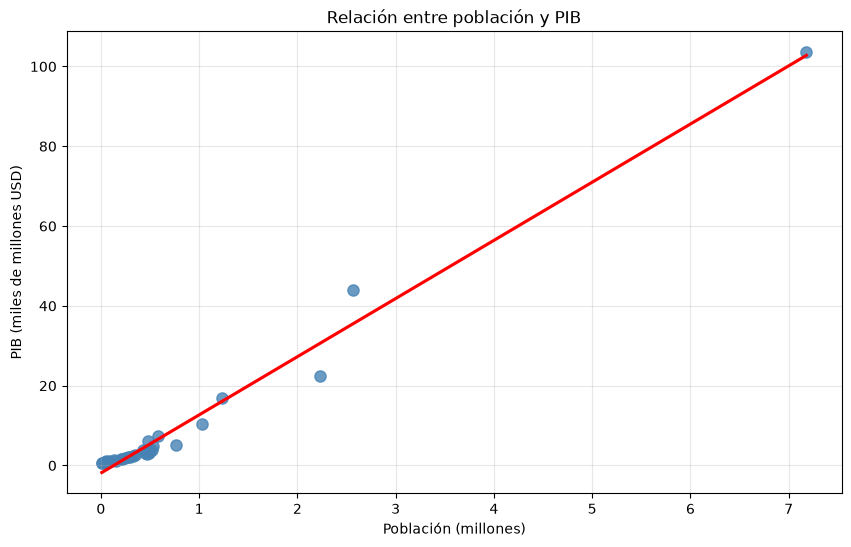

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=datos,
    x="Population (Millions)",
    y="GDP (USD Billion)",
    scatter_kws={"color": "steelblue", "s": 65},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Relación entre población y PIB")
plt.xlabel("Población (millones)")
plt.ylabel("PIB (miles de millones USD)")
plt.grid(alpha=0.3)
plt.show()


### Análisis punto 1.3

La covarianza entre el PIB (GDP) y la población es de **25,7957**, un valor positivo que indica que ambas variables tienden a aumentar conjuntamente.

Esto significa que las ciudades con mayor población, como Bogotá y Medellín, también tienden a presentar un mayor PIB, mientras que las ciudades menos pobladas generalmente tienen una menor actividad económica total.

**Conclusión:** Existe una relación positiva entre el tamaño poblacional y el PIB de las ciudades analizadas. Sin embargo, la covarianza no permite determinar por sí sola qué tan fuerte es esta relación, ya que depende de las unidades de medida. Para evaluar su intensidad utilizaremos la correlación en el punto 1.4.

## Punto 1.4.

¿Cuál es la correlación entre la variable X1 y X2? (Calcularla a mano).

In [11]:

import numpy as np

# Variables X1 y X2
x = datos["GDP (USD Billion)"]
y = datos["Population (Millions)"]

# Paso 1: Calcular las medias
media_x = x.mean()
media_y = y.mean()

# Paso 2: Diferencias respecto a la media
dif_x = x - media_x
dif_y = y - media_y

# Paso 3: Numerador
numerador = (dif_x * dif_y).sum()

# Paso 4: Denominador
suma_cuadrados_x = (dif_x ** 2).sum()
suma_cuadrados_y = (dif_y ** 2).sum()

denominador = (
    np.sqrt(suma_cuadrados_x) *
    np.sqrt(suma_cuadrados_y)
)

# Paso 5: Correlación
correlacion = numerador / denominador

print(f"Numerador: {numerador:.4f}")
print(f"Suma cuadrados X: {suma_cuadrados_x:.4f}")
print(f"Suma cuadrados Y: {suma_cuadrados_y:.4f}")
print(f"Denominador: {denominador:.4f}")
print(f"Correlación: {correlacion:.4f}")


Numerador: 773.8715
Suma cuadrados X: 11500.9550
Suma cuadrados Y: 53.0745
Denominador: 781.2855
Correlación: 0.9905


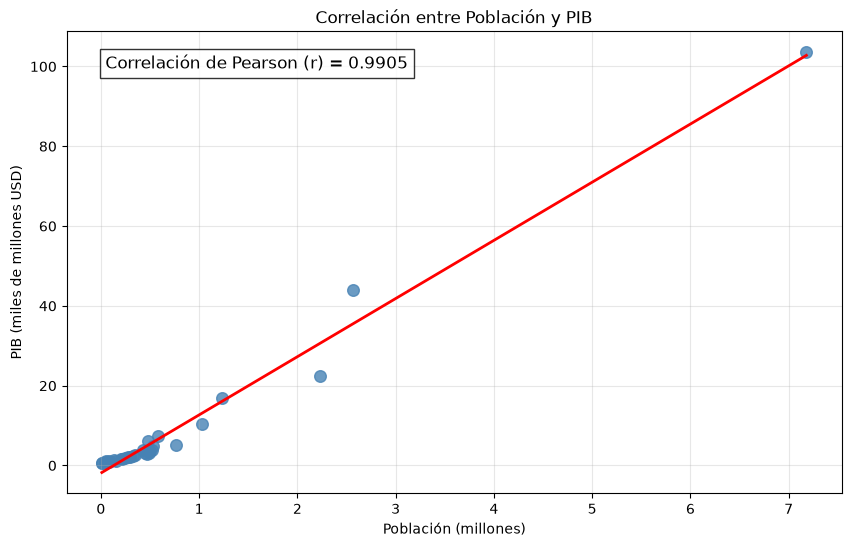

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

# Variables
x = datos["Population (Millions)"]
y = datos["GDP (USD Billion)"]

# Calcular correlación para mostrarla en el gráfico
r = x.corr(y)

plt.figure(figsize=(10, 6))

# Gráfico de dispersión con línea de tendencia
sns.regplot(
    x=x,
    y=y,
    ci=None,
    scatter_kws={"color": "steelblue", "s": 70},
    line_kws={"color": "red", "linewidth": 2}
)

# Mostrar el coeficiente
plt.text(
    0.05, 0.92,
    f"Correlación de Pearson (r) = {r:.4f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.title("Correlación entre Población y PIB")
plt.xlabel("Población (millones)")
plt.ylabel("PIB (miles de millones USD)")
plt.grid(alpha=0.3)

plt.show()


### Análisis punto 1.4

Aplicando la fórmula de correlación de Pearson indicada en el ejercicio, se obtuvo un coeficiente de **0.9905** entre el PIB y la población de las 30 ciudades colombianas.

Este resultado indica una relación lineal positiva muy fuerte, lo que significa que las ciudades con mayor población tienden a presentar un mayor PIB.

Sin embargo, esta relación no implica causalidad y puede estar influenciada por ciudades con valores elevados, como Bogotá y Medellín.

**Conclusión:** El PIB y la población presentan una asociación lineal positiva muy fuerte. Esto evidencia una relación entre el tamaño poblacional y la actividad económica total, aunque no permite concluir que una variable sea la causa directa de la otra.

## Punto 1.5.

Explique teórica y prácticamente la relación entre covarianza y correlación, enfatizando el efecto del escalamiento en la interpretación analítica de los datos.



Sustentación que demuestra que la covarianza cambia con la escala, pero la correlación permanece constante cuando las variables se multiplican por factores positivos

In [13]:

# Variables originales
pib = datos["GDP (USD Billion)"]
poblacion = datos["Population (Millions)"]

# Cambiar población de millones a miles
poblacion_miles = poblacion * 1000

# Calcular covarianzas poblacionales
cov_original = pib.cov(poblacion, ddof=0)
cov_escalada = pib.cov(poblacion_miles, ddof=0)

# Calcular correlaciones
corr_original = pib.corr(poblacion)
corr_escalada = pib.corr(poblacion_miles)

print("DATOS ORIGINALES")
print(f"Covarianza: {cov_original:.4f}")
print(f"Correlación: {corr_original:.4f}")

print("\nDATOS ESCALADOS")
print(f"Covarianza: {cov_escalada:.4f}")
print(f"Correlación: {corr_escalada:.4f}")


DATOS ORIGINALES
Covarianza: 25.7957
Correlación: 0.9905

DATOS ESCALADOS
Covarianza: 25795.7167
Correlación: 0.9905


### Analisis Punto 1.5:

La covarianza y la correlación describen la misma relación entre el PIB y la población. La diferencia está en la escala. 

En el punto 1.3 la covarianza poblacional fue 25,7957. 
En el punto 1.4 la correlación de Pearson fue 0,9905. 

Las dos salen del mismo numerador (773,8715), que es la suma de los productos de las desviaciones de cada ciudad respecto a su media.

La covarianza divide ese numerador entre N = 30, por eso conserva las unidades del producto: miles de millones de USD por millones de habitantes.
Un valor positivo indica que las dos variables se mueven en el mismo sentido, pero 25,7957 no dice si la relación es fuerte o débil. Si el PIB se midiera en millones de USD en lugar de miles de millones, cada dato quedaría multiplicado por 1.000 y la covarianza pasaría a 25.795,7. La relación entre las ciudades no cambió, solo cambió la unidad, y con ella el tamaño del número.

La correlación sale de la misma cuenta que la covarianza, pero se divide entre las desviaciones del PIB y de la población. Por eso da 0,9905, un número sin unidades, entre −1 y 1, que sí indica una relación lineal positiva muy fuerte. Esa división solo cuadra si la covarianza y las dos desviaciones usan el mismo N. Si el PIB se multiplica por 1.000, la covarianza cambia, pero la correlación se queda en 0,9905 porque la desviación del PIB también se multiplica por 1.000 y ese factor se anula.

Por lo tanto, la covarianza sirve para ver la dirección de la relación. La correlación sirve para ver su intensidad, sin que la unidad de medida distorsione la lectura. Ninguna de las dos demuestra que la población cause el PIB. El valor 0,9905 está influido por ciudades de gran tamaño, como Bogotá y Medellín, que alejan la nube de puntos y elevan tanto la covarianza como la correlación.


###  Punto 1.6:

Calcular el resultado del algoritmo K-means sobre este conjunto de datos sin utilizar librerías preconstruidas (demostrando el procedimiento en Python o Excel). Formar k=4 clusters e interpretar el perfil estadístico y conceptual de cada agrupamiento socioeconómico resultante.

K-means con k = 4, sin una librería de clustering. Cada ciudad empieza en el grupo de Initial label. Las variables de la distancia son PIB, población, desempleo y presupuesto. La ciudad es el nombre de la fila. Training no describe la economía de la ciudad. Mujeres y hombres suman 100, así que no entran las dos. La edad casi no separa ciudades.

Antes de medir distancias, cada variable se estandariza con su media y su desviación poblacional, la misma de los puntos anteriores. Sin ese paso, la distancia la decidiría el PIB.


In [14]:
columnas_kmeans = [
    "GDP (USD Billion)",
    "Population (Millions)",
    "Unemployment Rate (%)",
    "Budget (USD Billion)",
]

X = datos[columnas_kmeans].to_numpy(dtype=float)
media = X.mean(axis=0)
desviacion = np.sqrt(((X - media) ** 2).mean(axis=0))
Z = (X - media) / desviacion

grupo = datos["Initial label"].to_numpy(dtype=int)
k = 4

pd.DataFrame({
    "Variable": columnas_kmeans,
    "Media": media,
    "Desviación poblacional": desviacion,
}).round(4)


,Variable,Media,Desviación poblacional
0,GDP (USD Billion),8.7500,19.5797
1,Population (Millions),0.7310,1.3301
2,Unemployment Rate (%),13.8333,2.8956
3,Budget (USD Billion),1.6500,3.3932


El centro de un grupo es la media de sus ciudades, en las variables ya estandarizadas. La distancia es euclidiana. Si una ciudad queda a la misma distancia de dos centros, se queda en el grupo que ya tenía.


In [15]:
def centros(Z, grupo):
    C = np.zeros((k, Z.shape[1]))
    for j in range(k):
        miembros = Z[grupo == j]
        if len(miembros) > 0:
            C[j] = miembros.mean(axis=0)
    return C


def asignar(Z, C, grupo):
    nuevo = grupo.copy()
    distancias = np.zeros((len(Z), k))
    for i in range(len(Z)):
        distancias[i] = np.sqrt(((Z[i] - C) ** 2).sum(axis=1))
        minima = distancias[i].min()
        empatados = np.flatnonzero(np.isclose(distancias[i], minima))
        if grupo[i] in empatados:
            nuevo[i] = grupo[i]
        else:
            nuevo[i] = int(empatados[0])
    return nuevo, distancias


centros_iniciales = centros(Z, grupo)
grupo_vuelta_1, distancias_vuelta_1 = asignar(Z, centros_iniciales, grupo)

primera_vuelta = pd.DataFrame(distancias_vuelta_1, columns=[f"d{j}" for j in range(k)])
primera_vuelta.insert(0, "Ciudad", datos["City"])
primera_vuelta.insert(1, "Grupo inicial", grupo)
primera_vuelta["Grupo nuevo"] = grupo_vuelta_1
primera_vuelta["Cambió"] = grupo_vuelta_1 != grupo

print(f"Ciudades que cambian en la primera vuelta: {int(primera_vuelta['Cambió'].sum())} de {len(datos)}")
primera_vuelta.round(4)


Ciudades que cambian en la primera vuelta: 23 de 30


,Ciudad,Grupo inicial,d0,d1,d2,d3,Grupo nuevo,Cambió
0,Bogotá,2,9.1708,8.8232,7.9122,8.3691,2,False
1,Medellín,3,3.7461,3.3955,2.4458,2.8762,2,True
2,Cali,2,2.2174,1.8675,1.0321,1.4888,2,False
3,Barranquilla,3,1.6275,1.2802,0.3548,0.6983,2,True
4,Cartagena,1,1.7581,1.4615,0.8514,0.8722,2,True
5,Bucaramanga,2,2.0596,1.8671,1.5522,1.3908,3,True
6,Pereira,1,1.1071,0.8962,0.8853,0.5106,3,True
7,Cúcuta,1,0.6991,0.6323,1.2624,1.1140,1,False
8,Ibagué,3,0.6555,0.4064,0.8204,0.3681,3,False
9,Santa Marta,3,1.2031,1.0274,1.0535,0.6948,3,False


In [16]:
grupo_actual = grupo.copy()
historial = [grupo_actual.copy()]

for vuelta in range(1, 25):
    C = centros(Z, grupo_actual)
    grupo_nuevo, _ = asignar(Z, C, grupo_actual)
    cambios = int((grupo_nuevo != grupo_actual).sum())
    historial.append(grupo_nuevo.copy())
    print(
        f"Vuelta {vuelta}: {cambios} cambios. "
        f"Tamaños {[int((grupo_nuevo == j).sum()) for j in range(k)]}"
    )
    grupo_actual = grupo_nuevo
    if cambios == 0:
        break

grupo_final = grupo_actual


Vuelta 1: 23 cambios. Tamaños [10, 5, 5, 10]
Vuelta 2: 8 cambios. Tamaños [7, 9, 3, 11]
Vuelta 3: 4 cambios. Tamaños [6, 12, 2, 10]
Vuelta 4: 1 cambios. Tamaños [6, 13, 2, 9]
Vuelta 5: 0 cambios. Tamaños [6, 13, 2, 9]


In [17]:
perfil = datos[["City"] + columnas_kmeans].copy()
perfil["Grupo inicial"] = grupo
perfil["Grupo final"] = grupo_final

medias_globales = datos[columnas_kmeans].mean()
filas = []
for j in range(k):
    miembros = perfil[perfil["Grupo final"] == j]
    fila = {"Grupo": j, "n": len(miembros)}
    for columna in columnas_kmeans:
        fila[columna] = miembros[columna].mean()
    filas.append(fila)

resumen_grupos = pd.DataFrame(filas)
print("Media de cada grupo, en las unidades originales")
display(resumen_grupos.round(3))

print("Media de las 30 ciudades")
display(medias_globales.round(3).to_frame("Media general").T)

for j in range(k):
    ciudades = perfil.loc[perfil["Grupo final"] == j, "City"].tolist()
    nombres = ", ".join(ciudades)
    print(f"Grupo {j} ({len(ciudades)}): {nombres}")


Media de cada grupo, en las unidades originales


,Grupo,n,GDP (USD Billion),Population (Millions),Unemployment Rate (%),Budget (USD Billion)
0,0,6,1.900,0.232,18.417,0.417
1,1,13,2.277,0.299,13.900,0.485
2,2,2,73.800,4.875,10.850,12.750
3,3,9,8.211,0.767,11.344,1.689


Media de las 30 ciudades


,GDP (USD Billion),Population (Millions),Unemployment Rate (%),Budget (USD Billion)
Media general,8.75,0.731,13.833,1.65


Grupo 0 (6): Cúcuta, Sincelejo, Florencia, Quibdó, Mitú, Puerto Carreño
Grupo 1 (13): Ibagué, Villavicencio, Pasto, Montería, Valledupar, Neiva, Popayán, Armenia, Riohacha, San Andrés, Leticia, Arauca, Mocoa
Grupo 2 (2): Bogotá, Medellín
Grupo 3 (9): Cali, Barranquilla, Cartagena, Bucaramanga, Pereira, Santa Marta, Manizales, Tunja, Yopal


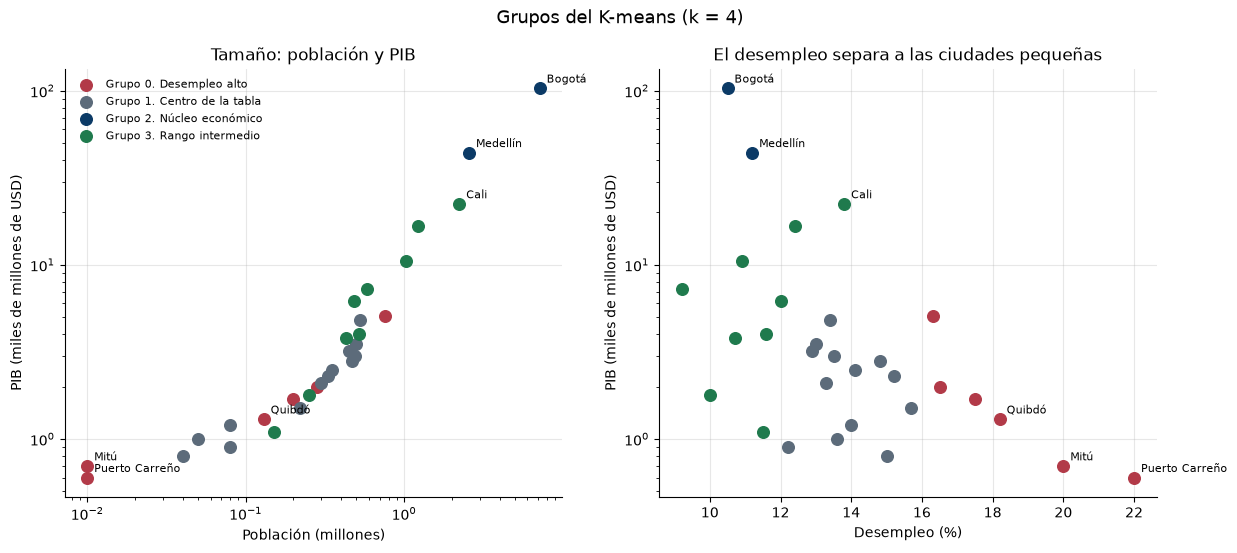

In [18]:
import matplotlib.pyplot as plt

colores = {
    0: "#B23A48",
    1: "#5C6B7A",
    2: "#0B3A66",
    3: "#1F7A4D",
}
nombres_grupo = {
    0: "Grupo 0. Desempleo alto",
    1: "Grupo 1. Centro de la tabla",
    2: "Grupo 2. Núcleo económico",
    3: "Grupo 3. Rango intermedio",
}
etiquetas = {"Bogotá", "Medellín", "Cali", "Quibdó", "Mitú", "Puerto Carreño"}

fig, ejes = plt.subplots(1, 2, figsize=(12.5, 5.6))

for j in range(k):
    sub = perfil[perfil["Grupo final"] == j]
    ejes[0].scatter(
        sub["Population (Millions)"],
        sub["GDP (USD Billion)"],
        s=70,
        color=colores[j],
        label=nombres_grupo[j],
        zorder=3,
    )
    ejes[1].scatter(
        sub["Unemployment Rate (%)"],
        sub["GDP (USD Billion)"],
        s=70,
        color=colores[j],
        zorder=3,
    )

for _, fila in perfil.iterrows():
    if fila["City"] not in etiquetas:
        continue
    for eje, x, y in (
        (ejes[0], fila["Population (Millions)"], fila["GDP (USD Billion)"]),
        (ejes[1], fila["Unemployment Rate (%)"], fila["GDP (USD Billion)"]),
    ):
        eje.annotate(
            fila["City"],
            (x, y),
            textcoords="offset points",
            xytext=(5, 4),
            fontsize=8,
        )

ejes[0].set_xscale("log")
ejes[0].set_yscale("log")
ejes[0].set_xlabel("Población (millones)")
ejes[0].set_ylabel("PIB (miles de millones de USD)")
ejes[0].set_title("Tamaño: población y PIB")
ejes[0].legend(frameon=False, fontsize=8, loc="upper left")

ejes[1].set_yscale("log")
ejes[1].set_xlabel("Desempleo (%)")
ejes[1].set_ylabel("PIB (miles de millones de USD)")
ejes[1].set_title("El desempleo separa a las ciudades pequeñas")

for eje in ejes:
    eje.grid(alpha=0.3)
    eje.spines["top"].set_visible(False)
    eje.spines["right"].set_visible(False)

fig.suptitle("Grupos del K-means (k = 4)", fontsize=13)
fig.tight_layout()
plt.show()


### Perfil de los grupos

El algoritmo se estabilizó en la vuelta 5. De las 30 ciudades, 23 cambiaron de grupo ya en la primera vuelta. Initial label sirvió para arrancar. No describe los grupos finales.

**Grupo 2. Bogotá y Medellín.** PIB medio 73,8, frente a 8,75 de toda la tabla. Población media 4,88 millones y presupuesto medio 12,75. El desempleo queda en 10,85 %, por debajo del 13,83 % general. Es el núcleo económico de la tabla: dos ciudades concentran tamaño, producto y presupuesto, con un mercado de trabajo menos apretado que el resto.

**Grupo 3. Nueve ciudades de rango intermedio:** Cali, Barranquilla, Cartagena, Bucaramanga, Pereira, Santa Marta, Manizales, Tunja y Yopal. El PIB medio es 8,21, cerca de la media de la tabla y muy por encima de su mediana. El desempleo medio es 11,34 %, también por debajo del promedio. Tunja y Yopal no entran por el tamaño. Entran porque, una vez estandarizado, su desempleo bajo las acerca a este grupo y no al de las ciudades pequeñas.

**Grupo 1. Trece ciudades.** PIB medio 2,28, población 0,30 millones, presupuesto 0,48 y desempleo 13,90 %. Es el grupo más grande y el más cercano al desempleo promedio de la tabla. Son ciudades pequeñas e intermedias, sin el extremo del mercado de trabajo.

**Grupo 0. Cúcuta, Sincelejo, Florencia, Quibdó, Mitú y Puerto Carreño.** El PIB medio es 1,90, parecido al del grupo 1. El desempleo medio es 18,42 %, claramente por encima. El algoritmo no las separó por ser más pequeñas. Las separó por el mercado de trabajo. Eso solo aparece porque las variables se estandarizaron. Si la distancia se hubiera calculado con el PIB en bruto, estas ciudades habrían quedado juntas con el grupo 1.

Los números 0, 1, 2 y 3 son las etiquetas con las que empezó el algoritmo. El perfil se lee en las medias, no en ese número.


## Punto 1.7.

Dendrograma con distancia máxima (enlace completo) sobre las mismas variables estandarizadas del K-means: PIB, población, desempleo y presupuesto. La distancia entre dos grupos es la mayor distancia entre una ciudad de uno y una ciudad del otro. El corte deja 4 grupos.


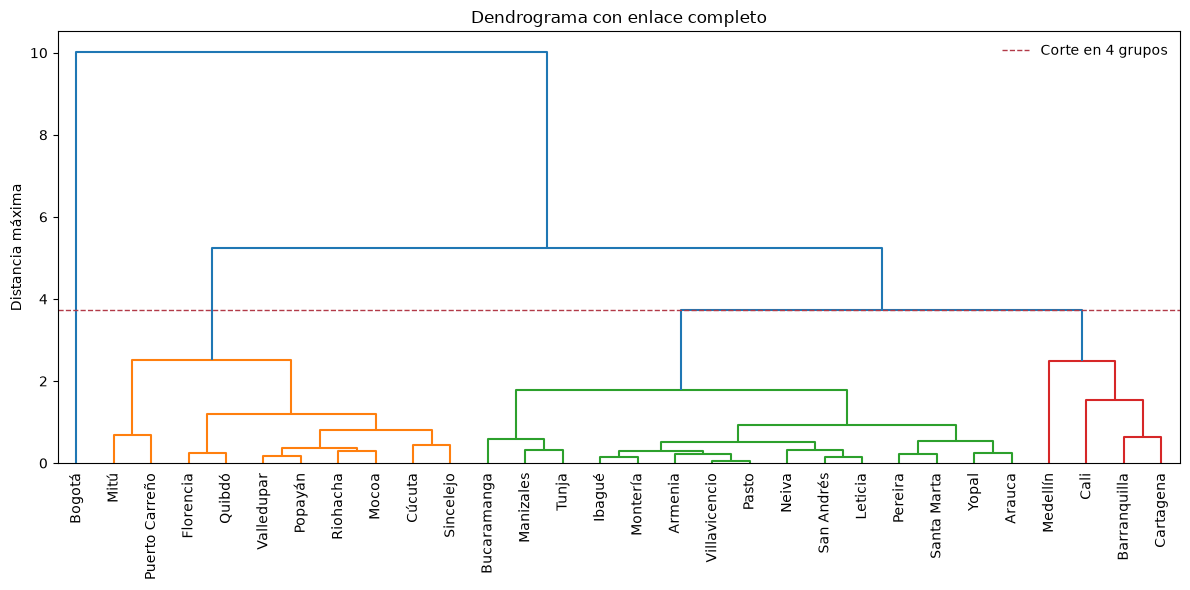

Ciudades en cada grupo del dendrograma
Grupo 1 (10): Cúcuta, Valledupar, Popayán, Sincelejo, Florencia, Riohacha, Quibdó, Mocoa, Mitú, Puerto Carreño
Grupo 2 (15): Bucaramanga, Pereira, Ibagué, Santa Marta, Manizales, Villavicencio, Pasto, Montería, Neiva, Armenia, Tunja, San Andrés, Yopal, Leticia, Arauca
Grupo 3 (4): Medellín, Cali, Barranquilla, Cartagena
Grupo 4 (1): Bogotá


In [19]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

enlace = linkage(Z, method="complete", metric="euclidean")
grupos_dendro = fcluster(enlace, t=4, criterion="maxclust")

corte = enlace[-3, 2]
fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(
    enlace,
    labels=datos["City"].tolist(),
    color_threshold=corte,
    ax=ax,
)
ax.set_ylabel("Distancia máxima")
ax.set_title("Dendrograma con enlace completo")
ax.axhline(corte, color="#B23A48", linestyle="--", linewidth=1, label="Corte en 4 grupos")
ax.legend(frameon=False)
plt.xticks(rotation=90)
fig.tight_layout()
plt.show()

print("Ciudades en cada grupo del dendrograma")
for j in sorted(set(grupos_dendro)):
    ciudades = datos.loc[grupos_dendro == j, "City"].tolist()
    print(f"Grupo {j} ({len(ciudades)}): {', '.join(ciudades)}")


In [20]:
filas_dendro = []
for j in sorted(set(grupos_dendro)):
    miembros = datos.loc[grupos_dendro == j, columnas_kmeans]
    fila = {"Grupo": j, "n": len(miembros)}
    for columna in columnas_kmeans:
        fila[columna] = miembros[columna].mean()
    filas_dendro.append(fila)

print("Medias del dendrograma, en unidades originales")
display(pd.DataFrame(filas_dendro).round(3))

comparacion = pd.DataFrame({
    "Ciudad": datos["City"],
    "K-means": grupo_final,
    "Dendrograma": grupos_dendro,
})
print("Ciudad, grupo de K-means y grupo del dendrograma")
display(comparacion)


Medias del dendrograma, en unidades originales


,Grupo,n,GDP (USD Billion),Population (Millions),Unemployment Rate (%),Budget (USD Billion)
0,1,10,1.880,0.245,17.120,0.40
1,2,15,3.093,0.349,12.333,0.66
2,3,4,23.450,1.765,12.075,4.40
3,4,1,103.500,7.180,10.500,18.00


Ciudad, grupo de K-means y grupo del dendrograma


,Ciudad,K-means,Dendrograma
0,Bogotá,2,4
1,Medellín,2,3
2,Cali,3,3
3,Barranquilla,3,3
4,Cartagena,3,3
5,Bucaramanga,3,2
6,Pereira,3,2
7,Cúcuta,0,1
8,Ibagué,1,2
9,Santa Marta,3,2


### Diferencia con el K-means

El corte del dendrograma deja cuatro grupos, pero no son los mismos del K-means.

**Bogotá queda sola.** En el K-means iba con Medellín. Con enlace completo, la distancia entre grupos es la distancia más grande entre sus ciudades. Bogotá está tan lejos del resto que unirla con cualquiera arrastra esa distancia máxima. Por eso el algoritmo la deja en su propio grupo.

**Medellín se junta con Cali, Barranquilla y Cartagena.** En el K-means, Medellín acompañaba a Bogotá, y Cali, Barranquilla y Cartagena iban con Bucaramanga, Pereira, Santa Marta, Manizales, Tunja y Yopal. El enlace completo separa a esas cuatro ciudades grandes del resto del rango intermedio.

**El grupo grande del dendrograma mezcla dos grupos del K-means.** Reúne a Bucaramanga, Pereira, Santa Marta, Manizales, Tunja y Yopal, que en K-means estaban en el rango intermedio, con Ibagué, Villavicencio, Pasto, Montería, Neiva, Armenia, San Andrés, Leticia y Arauca, que en K-means estaban en el grupo del centro de la tabla.

**El grupo de desempleo alto también cambia de miembros.** Cúcuta, Sincelejo, Florencia, Quibdó, Mitú y Puerto Carreño siguen juntos, igual que en el K-means. El dendrograma les suma Valledupar, Popayán, Riohacha y Mocoa. Esas cuatro estaban en el grupo 1 del K-means. El enlace completo las acerca al extremo porque mira la ciudad más lejana del grupo, no el centro.

K-means agrupa por cercanía al promedio del grupo. El enlace completo exige que todas las ciudades del grupo queden cerca, porque una sola ciudad lejana impide la unión. Por eso Bogotá se separa de Medellín y el corte entre ciudades pequeñas no es el mismo.
